# LAB | Micromanage your agents

**Scenario:** you are building an evaluation system for **one specific use case**. Public benchmarks (like HLE in class) don't reflect your client's real questions, so you build **your own dataset**, upload it to LangSmith, run experiments and report what you found.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- **Hints** point to the lesson notebook (`02_langsmith(1).ipynb`), where you saw each idea.
- Markdown cells with a bold prompt (e.g. **Document your choice here:**, **Key findings:**) are for your written answers.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Choose a domain + set up LangSmith | Tracing, projects, regions |
| 2 | Build and upload your own dataset | Datasets: inputs, reference outputs, metadata |
| 3 | Write the target function + evaluators | Target, LLM-as-a-judge (OpenEvals), exact match |
| 4 | Run the experiment and review it in the UI | `client.evaluate()`, experiments, feedback |
| 5 | Analyse results + write `evaluation_summary.md` | Metrics, error analysis |
| Optional 1 | Design a custom evaluator | Judge prompt anatomy (notebook 01) |
| Optional 2 | A/B test models on cost vs performance | Model comparison, cost per correct answer |

In [1]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Part 1: Setup & document selection (30–45 min)
### Step 1: Choose your domain and documents

**Document your choice here:**
- **Domain:** EU AI Act advisory Q&A for AI consultants. A client asks an external consultant things like "is my use case banned?", "is it high-risk?", "who is the provider?", "when do the rules apply?" or "do we need a FRIA?". Wrong answers cost the client real money and legal exposure: a banned use nobody stopped, a project planned against an outdated deadline, or an over-confident "you're compliant".
- **Sources:** the Ironhack W7 lesson decks *Compliance, Legal, and the AI Consultant* (Lesson 1, 33 slides) and *EU AI Act for Consultants* (Lesson 2, 54 slides). Both reflect the AI Act as amended by the **Digital Omnibus** (Regulation (EU) 2026/1744, in force 27 July 2026). I cross-checked the Omnibus dates against published law-firm summaries (White & Case, Orrick, CMS, July 2026). The examples are in `data/eu_ai_act_qa_dataset.json`.
- **One example:** *"From what date do the high-risk obligations apply to stand-alone Annex III AI systems such as CV-screening tools?"* → *"From 2 December 2027. The Digital Omnibus postponed the original 2 August 2026 date."*
- **What makes a good answer:**
  1. The right **conclusion** first (risk level, yes/no, role, date).
  2. The **key facts** behind it, correct: article, deadline, threshold, fine.
  3. It **stays in the consultant's lane**: it never confirms compliance, and it flags grey areas for a lawyer.

**Trap examples built in:**
- 3 questions depend on the July 2026 Omnibus, which is newer than most models' training data (`post_cutoff_fact = True`).
- The rest test classic traps from the lesson:
  - the narrow-task exception
  - "you need an outside inspector"
  - FRIA triggers
  - an editor-reviewed AI text needing no label

### Step 2: Set up LangSmith

 **Hint:** copy the setup pattern from `02_langsmith(1).ipynb` (Setup: keys and region). Your `.env` needs `LANGSMITH_API_KEY` and `OPENAI_API_KEY`. Check your **region**: `eu.smith.langchain.com` in the browser means EU.

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()   # reads OPENAI_API_KEY and LANGSMITH_API_KEY from .env in this folder

# Tracing on, a descriptive project name, and my region (EU account: eu.smith.langchain.com)
os.environ["LANGSMITH_TRACING"] = "true"
PROJECT_NAME = "lab-langsmith-eu-ai-act"
os.environ["LANGSMITH_PROJECT"] = PROJECT_NAME
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"   # US: https://api.smith.langchain.com

for key in ("OPENAI_API_KEY", "LANGSMITH_API_KEY"):
    print(f"{key}: {'found' if os.getenv(key) else 'MISSING, check your .env'}")

OPENAI_API_KEY: found
LANGSMITH_API_KEY: found


In [3]:
import json
import re
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # charts and CSVs are saved here

# LangSmith client, and an OpenAI client WRAPPED so that every call is traced
client = Client()
openai_client = wrap_openai(OpenAI())

# Verify the connection
datasets_visible = list(client.list_datasets())
print(f"Connected to LangSmith ({os.environ['LANGSMITH_ENDPOINT']}). Datasets visible: {len(datasets_visible)}")

Connected to LangSmith (https://eu.api.smith.langchain.com). Datasets visible: 1


## Part 2: Dataset creation (60–90 min)
### Step 3: Extract and structure your examples

Turn your documents into a list of examples. Every example is a dictionary with the **same keys**.

| Field | Goes to | Example |
|---|---|---|
| `question` (+ `context` if RAG-style) | **inputs**: what the model sees | "Can I return a sale item?" |
| `answer` | **outputs**: the reference answer | "Yes, within 14 days, store credit only." |
| `category`, `difficulty`, `source` | **metadata**: for analysis, the model never sees it | "returns", "hard", "policy.pdf p.3" |

 **Hint:** aim for **15–20 examples** (minimum 10). Include at least 2 categories and at least 2 "hard" or "trap" examples.

In [4]:
# Option B: load from a file. I wrote the 18 examples by hand from the lesson slides into a JSON file
# (easier to review and version than a giant Python list).
examples = json.loads(Path("data/eu_ai_act_qa_dataset.json").read_text(encoding="utf-8"))

print(f"Loaded {len(examples)} examples. One of them:\n")
print(json.dumps(examples[4], indent=2, ensure_ascii=False))

Loaded 18 examples. One of them:

{
  "question": "From what date do the high-risk obligations apply to stand-alone Annex III AI systems such as CV-screening or credit-scoring tools?",
  "answer": "From 2 December 2027. The original date was 2 August 2026, but the Digital Omnibus (Regulation (EU) 2026/1744, in force since 27 July 2026) postponed it by 16 months. Client plans built on 'high-risk from August 2026' are out of date.",
  "must_include": [
    [
      "2 december 2027",
      "december 2, 2027",
      "2 dec 2027",
      "2nd december 2027"
    ]
  ],
  "category": "timeline",
  "difficulty": "hard",
  "source": "Lesson 1 slide 11; Lesson 2 slides 23, 27, 51",
  "post_cutoff_fact": true
}


In [5]:
# 1. At least 10 examples?
assert len(examples) >= 10, "Need at least 10 examples"

# 2. Same keys everywhere, no empty question / answer, no duplicates
expected_keys = set(examples[0])
for i, ex in enumerate(examples):
    assert set(ex) == expected_keys, f"Example {i} has different keys: {set(ex) ^ expected_keys}"
    assert ex["question"].strip() and ex["answer"].strip(), f"Example {i} has an empty question or answer"
    assert ex["must_include"], f"Example {i} has no key terms"
assert len({ex["question"] for ex in examples}) == len(examples), "Duplicate questions"

# 3. Distribution per category / difficulty / post-cutoff
overview = pd.DataFrame(examples)
print(f"{len(examples)} examples passed all checks\n")
print(overview["category"].value_counts().to_string(), "\n")
print(overview["difficulty"].value_counts().to_string(), "\n")
print("Depends on the July 2026 Digital Omnibus:", int(overview["post_cutoff_fact"].sum()))

18 examples passed all checks

category
prohibited_practices    3
timeline                3
high_risk_duties        3
risk_classification     2
transparency            2
roles                   1
fria                    1
gpai                    1
fines                   1
consultant_role         1 

difficulty
medium    8
hard      6
easy      4 

Depends on the July 2026 Digital Omnibus: 3


**My data structure:**

| Field | Goes to | Meaning |
|---|---|---|
| `question` | **inputs** | A client question, often a short business scenario. One question per example; examples are independent. |
| `answer` | **outputs** | Reference answer from the slides: the conclusion first, then the facts that must not be contradicted. |
| `must_include` | **outputs** | Key terms for the rule-based evaluator: a list of groups, and each group lists acceptable spellings. Every group must appear, e.g. `[["2 december 2027", "december 2, 2027"]]`. |
| `category` | metadata | One of 10 topics: prohibited_practices, timeline, high_risk_duties, risk_classification, transparency, roles, fria, gpai, fines, consultant_role. |
| `difficulty` | metadata | **easy**: a single well-known rule. **medium**: a rule with a condition. **hard**: a lesson trap or a post-2025 date. |
| `source` | metadata | Slide numbers, for traceability. |
| `post_cutoff_fact` | metadata | `True` if the answer depends on the July 2026 Omnibus. It isolates failures caused by stale training data. |

**What I changed:**
- I dropped `context`. This is a closed-book test of what the model knows; the A/B part adds context back as a "regulatory briefing".
- I checked that every reference answer passes its own `must_include` check.

### Step 4: Create the LangSmith dataset

 **Hints (§2 of `02_langsmith(1).ipynb`):**
- Check `client.list_datasets()` first, so re-running the cell doesn't create a duplicate.
- `client.create_dataset(name, description=...)` then `client.create_examples(inputs=[...], outputs=[...], metadata=[...], dataset_id=...)`.
- Put a **version** in the name (e.g. `-v1`). If you change the examples later, create `-v2` instead of editing silently.

In [6]:
DATASET_NAME = "eu-ai-act-consultant-qa-v1"
DATASET_DESCRIPTION = (
    "18 EU AI Act questions a client asks an AI consultant (risk levels, Article 5 bans, provider/deployer, "
    "high-risk duties, FRIA, GPAI, transparency, fines, Digital Omnibus timeline). Reference answers from "
    "the Ironhack W7 lesson decks, reflecting the AI Act as amended by Regulation (EU) 2026/1744."
)

INPUT_KEYS = ["question"]
OUTPUT_KEYS = ["answer", "must_include"]
META_KEYS = ["category", "difficulty", "source", "post_cutoff_fact"]

# Create the dataset only if it doesn't exist yet, then upload inputs, outputs AND metadata
existing = {d.name for d in client.list_datasets()}
if DATASET_NAME not in existing:
    dataset = client.create_dataset(DATASET_NAME, description=DATASET_DESCRIPTION)
    client.create_examples(
        inputs   = [{k: ex[k] for k in INPUT_KEYS} for ex in examples],
        outputs  = [{k: ex[k] for k in OUTPUT_KEYS} for ex in examples],
        metadata = [{k: ex[k] for k in META_KEYS} for ex in examples],
        dataset_id = dataset.id,
    )
    print(f"Created '{DATASET_NAME}' with {len(examples)} examples")
else:
    print(f"'{DATASET_NAME}' already exists, skipping upload")

# Verify: count the examples now stored in LangSmith
stored = list(client.list_examples(dataset_name=DATASET_NAME))
print(f"Examples stored in LangSmith: {len(stored)} (expected {len(examples)})")
print("Sample metadata:", stored[0].metadata)

'eu-ai-act-consultant-qa-v1' already exists, skipping upload
Examples stored in LangSmith: 18 (expected 18)
Sample metadata: {'source': 'Lesson 1 slide 24; Lesson 2 slides 35-36', 'category': 'roles', 'difficulty': 'medium', 'dataset_split': ['base'], 'post_cutoff_fact': False}


**Go and look:** open **Datasets → your dataset** in LangSmith. Are inputs, reference outputs and metadata all there? Take a **screenshot** for your repo → `outputs/screenshot_dataset.png`.

**Dataset name + description:** `eu-ai-act-consultant-qa-v1`. 18 EU AI Act questions a client asks an AI consultant, covering risk levels, Article 5 bans, provider/deployer, high-risk duties, FRIA, GPAI, transparency, fines and the Digital Omnibus timeline. The reference answers come from the Ironhack W7 lesson decks and reflect the AI Act as amended by Regulation (EU) 2026/1744.

## Part 3: Evaluation setup (45–60 min)
### Step 5: Target function

The target is **the system under test**: it takes `inputs` from one example and returns `outputs`.

 **Hints (§3 of `02_langsmith(1).ipynb`):**
- Signature: `def target(inputs: dict) -> dict`, returning e.g. `{"answer": "..."}`.
- Add `@traceable` so the whole function (not only the OpenAI call) appears as one trace.
- Set `temperature=0` for controlled randomness (§5 Reproducibility: still not 100% guaranteed).
- **gpt-5 family:** use `max_completion_tokens` instead of `max_tokens`, and `reasoning_effort="none"` for short direct answers.
- **Error handling:** wrap the API call in `try/except` and return `{"answer": "", "error": str(e)}`, so one failure doesn't stop the whole experiment.

In [7]:
MODEL = "gpt-4o-mini"

SYSTEM_PROMPT = """You are an assistant for AI consultants advising EU companies on the EU AI Act
(Regulation (EU) 2024/1689).

Answer the client question in at most 120 words:
- Give the direct answer first (e.g. the risk level, yes/no, the date or the number).
- Name the relevant article or annex when you know it.
- If dates matter, give the date that applies today.
- You are not a lawyer: never confirm that a client "is compliant". Flag grey areas
  that need a lawyer instead of deciding them."""


def call_model(model: str, system: str, question: str) -> dict:
    """One chat call with the right parameters for the model family.
    gpt-4o family: temperature=0 + max_tokens. gpt-5 family: max_completion_tokens + reasoning_effort="none"."""
    params = ({"max_completion_tokens": 600, "reasoning_effort": "none"} if model.startswith("gpt-5")
              else {"temperature": 0, "max_tokens": 400})
    start = time.perf_counter()
    r = openai_client.chat.completions.create(
        model=model,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
        **params,
    )
    return {
        "answer": (r.choices[0].message.content or "").strip(),
        "prompt_tokens": r.usage.prompt_tokens,
        "completion_tokens": r.usage.completion_tokens,
        "latency_s": round(time.perf_counter() - start, 2),
    }


@traceable(name="lab-target")
def target(inputs: dict) -> dict:
    try:
        return call_model(MODEL, SYSTEM_PROMPT, inputs["question"])
    except Exception as e:   # one failure must not stop the whole experiment
        return {"answer": "", "error": str(e)}

In [8]:
# Test the target on 3 examples BEFORE running the full evaluation (incl. one post-cutoff trap)
for ex in examples[:2] + [examples[4]]:
    out = target({"question": ex["question"]})
    print("Q  :", ex["question"])
    print("A  :", out.get("answer") or f"ERROR {out.get('error')}")
    print("REF:", ex["answer"])
    print(f"     tokens {out.get('prompt_tokens')}+{out.get('completion_tokens')}, {out.get('latency_s')}s\n")

Q  : A client wants an AI that reads employees' faces and voices in video calls to give each person an 'engagement score'. Which EU AI Act risk level does this fall under?
A  : This AI application falls under the high-risk category according to Annex III of the EU AI Act, specifically related to biometric identification and categorization of natural persons. However, the classification may depend on specific use cases and context, which could introduce grey areas. It is advisable to consult a legal expert to ensure compliance with all relevant provisions and to assess any potential implications.
REF: Prohibited. Emotion recognition in the workplace (or in education) is a banned practice under Article 5(1)(f), apart from narrow medical or safety exceptions. There is no compliance path: the consultant should stop the work, escalate and document it.
     tokens 163+72, 1.48s

Q  : An insurer wants a 'TrustScore' for every customer that combines payment history, social-media behaviour, lif

### Step 6: Evaluators

 **Hints:**
- Correctness: OpenEvals `CORRECTNESS_PROMPT` + `create_llm_as_judge(...)`, exactly as in §3 of `02_langsmith(1).ipynb`.
- Use a **different (stronger) model as judge** than the model under test.
- Exact match only makes sense when answers are short labels (a letter, a category, a number). For free-text answers, skip it or use a keyword check instead.
- An evaluator function returns a dict like `{"key": "my_metric", "score": True}`.

In [9]:
JUDGE_MODEL = "gpt-5.4-mini"   # stronger and newer than the model under test (gpt-4o-mini)

# Correctness evaluator: OpenEvals CORRECTNESS_PROMPT as LLM-as-a-judge.
# I pass the wrapped OpenAI client as judge (no LangChain dependency needed); judge calls are traced too.
_correctness_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    judge=openai_client,
    model=JUDGE_MODEL,
    feedback_key="correctness",
)

def correctness_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    # Only the answer texts go to the judge (not token counts or the key-term list)
    return _correctness_judge(
        inputs=inputs["question"],
        outputs=outputs.get("answer", ""),
        reference_outputs=reference_outputs["answer"],
    )

# Cheap, deterministic evaluator without an LLM: "does the answer contain the key term(s)?"
# Each group in must_include lists acceptable spellings; every group must appear (case-insensitive).
def rule_evaluator(outputs: dict, reference_outputs: dict) -> dict:
    answer = outputs.get("answer", "").lower()
    groups = reference_outputs["must_include"]
    missing = [g[0] for g in groups if not any(term.lower() in answer for term in g)]
    return {
        "key": "keyword_match",
        "score": not missing,
        "comment": "all key terms present" if not missing else f"missing: {missing}",
    }

In [10]:
# Test the evaluators on 1 correct and 1 deliberately wrong answer (the classic stale-date error)
ex = examples[4]
inp, ref = {"question": ex["question"]}, {"answer": ex["answer"], "must_include": ex["must_include"]}
cases = {
    "correct": {"answer": "From 2 December 2027. The Digital Omnibus delayed the original August 2026 date."},
    "wrong (stale date)": {"answer": "High-risk obligations for Annex III systems apply from 2 August 2026."},
}
for label, out in cases.items():
    c = correctness_evaluator(inp, out, ref)
    r = rule_evaluator(out, ref)
    print(f"{label:<20} correctness={c['score']!s:<6} keyword_match={r['score']!s:<6} ({r['comment']})")
    print("   judge says:", c["comment"][:200], "\n")

correct              correctness=True   keyword_match=True   (all key terms present)
   judge says: The response correctly states that the high-risk obligations for stand-alone Annex III AI systems such as CV-screening or credit-scoring tools apply from 2 December 2027, which matches the reference.  

wrong (stale date)   correctness=False  keyword_match=False  (missing: ['2 december 2027'])
   judge says: The response states that high-risk obligations for Annex III systems apply from 2 August 2026, but the reference says this date was postponed by 16 months and now applies from 2 December 2027. Therefo 



**What does "correct" mean in my domain?** Each question has **one legally right conclusion**, but many valid wordings ("prohibited" = "banned", "2 December 2027" = "December 2, 2027"). So exact match is useless, and a semantic judge is needed.

| Evaluator | Type | Measures | Weakness |
|---|---|---|---|
| `correctness` | LLM-as-a-judge (OpenEvals `CORRECTNESS_PROMPT`, gpt-5.4-mini) | Does the answer convey the same conclusion and facts as the reference? | Can be lenient on a wrong date if the rest of the answer is right; costs money |
| `keyword_match` | Rule-based, free | Are the decisive terms present (the date, the risk level, "self-assessment")? | Blind to meaning: "not 2 December 2027" would pass, and a correct synonym I didn't list would fail |

The two are complementary: rows where they **disagree** are the most interesting to read in Step 8.

## Part 4: Run the evaluation (30–45 min)
### Step 7: Execute the experiment

 **Hint (§3 of `02_langsmith(1).ipynb`):** `client.evaluate(target, data=..., evaluators=[...], experiment_prefix=..., max_concurrency=2)`. Use a prefix that tells you **what** ran, e.g. `"gpt-4o-mini-promptv1"`.

In [11]:
results = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[correctness_evaluator, rule_evaluator],
    experiment_prefix="gpt-4o-mini-consultant-promptv1",
    description="gpt-4o-mini, temperature 0, consultant system prompt, closed-book",
    metadata={"model": MODEL, "judge": JUDGE_MODEL},
    max_concurrency=2,
)
print(results)

/opt/anaconda3/envs/bootcamp-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


View the evaluation results for experiment: 'gpt-4o-mini-consultant-promptv1-3b7ab57c' at:
https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548/compare?selectedSessions=bd7d9f69-a521-4ac9-911a-077af842eedd




18it [00:15,  1.16it/s]

<ExperimentResults gpt-4o-mini-consultant-promptv1-3b7ab57c>


In [12]:
def add_judge_comments(res, frame):
    """to_pandas() keeps scores only; pull each evaluator's comment (the judge's reasoning) from the results."""
    rows = {}
    for row in res:
        ex_id = str(row["example"].id)
        for er in row["evaluation_results"]["results"]:
            rows.setdefault(ex_id, {})[f"feedback.{er.key}.comment"] = er.comment
    comments = pd.DataFrame.from_dict(rows, orient="index").rename_axis("example_id").reset_index()
    frame = frame.copy()
    frame["example_id"] = frame["example_id"].astype(str)
    return frame.merge(comments, on="example_id", how="left")

# Collect the results and check that EVERY example was processed
df = add_judge_comments(results, results.to_pandas())
print(df.columns.tolist())    # inputs.*, outputs.*, reference.*, feedback.*, execution_time, example_id ...

n_errors = int(df["outputs.error"].notna().sum()) if "outputs.error" in df else 0
print(f"\nRows: {len(df)} / {len(examples)} examples | target errors: {n_errors}")
assert len(df) == len(examples), "Some examples were not processed"
df.to_csv(OUT / "results_main.csv", index=False)

['inputs.question', 'outputs.answer', 'outputs.prompt_tokens', 'outputs.completion_tokens', 'outputs.latency_s', 'error', 'reference.answer', 'reference.must_include', 'feedback.correctness', 'feedback.keyword_match', 'execution_time', 'example_id', 'id', 'feedback.correctness.comment', 'feedback.keyword_match.comment']

Rows: 18 / 18 examples | target errors: 0


### Step 8: Review the results in the LangSmith UI

**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo → `outputs/`.

**First observations + experiment link:**
- Experiments are in the dataset view [eu-ai-act-consultant-qa-v1](https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548), prefix `gpt-4o-mini-consultant-promptv1`.
- The results table is almost all red. The answers *read* well: structured, cite articles, end with "consult a lawyer". But the articles are often the wrong ones: Art. 52, 62 and 71 are the numbering from the 2021 draft.
- I read the judge comments on 3 failures. Each one names a concrete wrong fact (fines, log retention, conformity assessment) rather than a style issue, so I trust the low score.
- The judge and the keyword rule agree on 16 of 18 rows. The 2 disagreements are correct answers worded differently from my key terms: "significantly" instead of "substantial", and no explicit "narrow task" wording.

## Part 5: Analysis & reporting (45–60 min)
### Step 9: Analyse results

In [13]:
# Aggregate metrics for each evaluator: mean (= pass rate for True/False), n, number failed
feedback_cols = [c for c in df.columns if c.startswith("feedback.") and not c.endswith(".comment")]
metrics = pd.DataFrame({
    col.removeprefix("feedback."): {
        "pass_rate": df[col].astype(float).mean(),
        "n": int(df[col].notna().sum()),
        "failed": int((df[col].astype(float) == 0).sum()),
    } for col in feedback_cols
}).T
metrics["pass_rate"] = metrics["pass_rate"].round(3)
print(metrics)
print(f"\nAvg latency per example: {df['execution_time'].mean():.2f}s")
metrics.to_csv(OUT / "metrics_main.csv")

               pass_rate     n  failed
correctness        0.167  18.0    15.0
keyword_match      0.056  18.0    17.0

Avg latency per example: 1.40s


,correct,keyword
category,,
fines,0.0,0.0
fria,0.0,0.0
gpai,0.0,0.0
high_risk_duties,0.0,0.0
prohibited_practices,0.0,0.0
timeline,0.0,0.0
transparency,0.0,0.0
risk_classification,0.5,0.0
consultant_role,1.0,1.0


,correct,keyword
difficulty,,
easy,0.00,0.00
medium,0.38,0.12
hard,0.00,0.00


correct      keyword     
                    mean size    mean size
post_cutoff_fact                          
False                0.2   15    0.07   15
True                 0.0    3    0.00    3

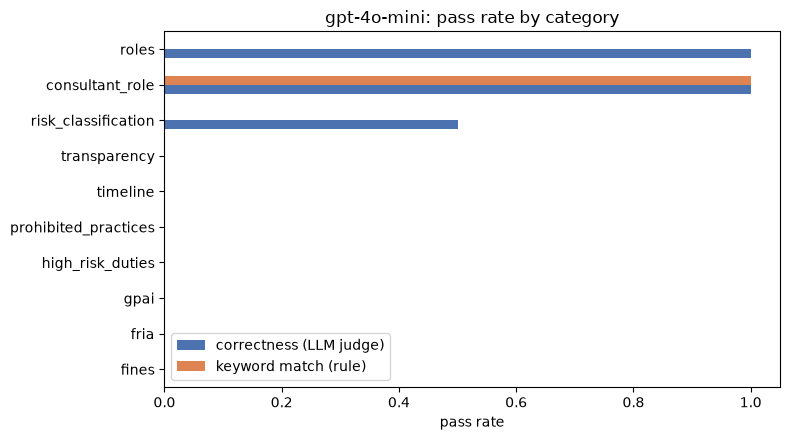

In [14]:
# Performance by category and by difficulty
# The results DataFrame has no metadata, so join it from the dataset:
meta = pd.DataFrame([
    {"example_id": str(e.id), **(e.metadata or {})}
    for e in client.list_examples(dataset_name=DATASET_NAME)
])
df["example_id"] = df["example_id"].astype(str)
df = df.merge(meta, on="example_id", how="left")

df["correct"] = df["feedback.correctness"].astype(float)
df["keyword"] = df["feedback.keyword_match"].astype(float)

by_category = df.groupby("category")[["correct", "keyword"]].mean().sort_values("correct")
by_difficulty = df.groupby("difficulty")[["correct", "keyword"]].mean().reindex(["easy", "medium", "hard"])
by_cutoff = df.groupby("post_cutoff_fact")[["correct", "keyword"]].agg(["mean", "size"])
display(by_category.round(2)); display(by_difficulty.round(2)); display(by_cutoff.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
by_category.plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_xlim(0, 1.05); ax.set_xlabel("pass rate"); ax.set_ylabel("")
ax.set_title("gpt-4o-mini: pass rate by category"); ax.legend(["correctness (LLM judge)", "keyword match (rule)"])
plt.tight_layout(); plt.savefig(OUT / "pass_rate_by_category.png", dpi=120); plt.show()

In [15]:
# Error analysis
# 1. Show every example that failed EITHER evaluator: question, model answer, reference, judge comment
fails = df[(df["correct"] == 0) | (df["keyword"] == 0)].copy()
print(f"{len(fails)} examples failed at least one evaluator\n")
for _, r in fails.iterrows():
    print(f"[{r['category']} | {r['difficulty']} | post-cutoff={r['post_cutoff_fact']}] "
          f"correctness={bool(r['correct'])}  keyword={bool(r['keyword'])}")
    print("Q      :", r["inputs.question"])
    print("A      :", r["outputs.answer"])
    print("REF    :", r["reference.answer"])
    print("JUDGE  :", str(r.get("feedback.correctness.comment", ""))[:400], "\n")

# 2. Give each failure a type by hand after reading the output above:
#    wrong fact / incomplete / hallucination / stale knowledge / wrong format / judge mistake / bad reference / keyword miss
FAILURE_TYPES = {
    # "question start ...": "stale knowledge",
}
fails["failure_type"] = fails["inputs.question"].map(
    lambda q: next((t for k, t in FAILURE_TYPES.items() if q.startswith(k)), "untagged"))
fails[["category", "difficulty", "post_cutoff_fact", "correct", "keyword", "failure_type",
       "inputs.question", "outputs.answer", "reference.answer"]].to_csv(OUT / "failures_main.csv", index=False)
print(fails["failure_type"].value_counts())

17 examples failed at least one evaluator

[roles | medium | post-cutoff=False] correctness=True  keyword=False
Q      : An HR software company builds a CV-screening tool and sells it under its own name. A retail chain buys it to hire staff. Who is the provider and who is the deployer? Can the deployer become a provider?
A      : The HR software company is the provider of the CV-screening tool, while the retail chain is the deployer. According to Article 3(1) of the EU AI Act, the provider is the entity that develops or puts the AI system on the market, and the deployer is the entity that uses the AI system in its operations. 

Yes, the deployer can become a provider if they modify or enhance the AI system significantly before offering it to others. However, this may involve legal complexities, so consulting a lawyer is advisable to clarify obligations and compliance.
REF    : The HR software company is the provider; the retail chain is the deployer. A deployer becomes the provider of 

**Key findings:**
1. **Overall pass rate per evaluator:** correctness (LLM judge) **17%** (3 of 18); keyword match **6%** (1 of 18); advisory quality **0.61** (separate run).
2. **Easiest and hardest category:**
   - Easiest: `roles` and `consultant_role`, both correct. These questions reward general reasoning, not specific facts.
   - Hardest, all at 0%: `timeline`, `prohibited_practices`, `high_risk_duties`, `fines`, `fria`, `gpai`, `transparency`. `risk_classification` scored 50%. These need exact facts from the final Act, or from the 2026 Omnibus.
3. **Biggest failure pattern: answering from the wrong version of the law.** gpt-4o-mini uses the 2021 Commission proposal:
   - Fines of "€30 million or 6% (Article 71)" instead of €35M / 7%.
   - "Article 52" for labelling instead of Article 50.
   - It misses all 3 Article 5 bans. For example, emotion recognition at work is called "high-risk under Annex III" instead of prohibited.
   - On Omnibus questions it invents dates, and different ones per run at temperature 0: "1 January 2025", then "6 April 2025".

   Failure types across the 15 failures: wrong fact 4 · missed ban 3 · stale knowledge 3 · incomplete 3 · over-generalisation 2.
4. **Judge mistakes or bad references?**
   - None in the main run.
   - In the A/B run, the judge marked gpt-5.4-mini's face-scraping answer **correct** although it called the practice "high-risk". The keyword rule passed it too. Both evaluators are lenient when the bottom line is right but the legal category is wrong.
   - Some references are deliberate simplifications ("at least 6 months" of logs). gpt-5.4-mini's "no single fixed period" is arguably more precise but was marked wrong.

**Remember (W7/D5 statistics):** with 18 examples every score is an **estimate**. The same gpt-4o-mini setup scored 11% to 17% across runs, so a gap of 1 example is noise.

### Step 10: `evaluation_summary.md`

**One short paragraph** (plus optional bullets/table): what you evaluated, main metrics, biggest failure pattern, limitations, one recommendation. Not a long report.

In [31]:
# Draft built from the computed numbers. I rewrite the narrative sentences after reading the failures.
corr, kw = df["correct"].mean(), df["keyword"].mean()
post = df[df["post_cutoff_fact"] == True]["correct"].mean()
pre = df[df["post_cutoff_fact"] == False]["correct"].mean()
hardest = by_category["correct"].idxmin()

summary = f'''# Evaluation summary

I evaluated a **gpt-4o-mini** "EU AI Act consultant assistant" (temperature 0, consultant system prompt,
closed-book) on **{DATASET_NAME}**: {len(df)} client questions built from the Ironhack W7 lesson decks,
covering 10 categories, with {int((df["difficulty"] == "hard").sum())} hard examples and {int(df["post_cutoff_fact"].sum())} that depend on the
July 2026 Digital Omnibus. An OpenEvals LLM-as-a-judge (`CORRECTNESS_PROMPT`, {JUDGE_MODEL}) passed
**{corr:.0%}** of answers, and a rule-based key-term check passed **{kw:.0%}**. Accuracy was **{post:.0%}** on
Omnibus-dependent questions against **{pre:.0%}** on the rest; the weakest category was **{hardest}**.
Biggest failure pattern: [fill after error analysis]. Limitations: 18 examples (one example is about
5.6 points), a single judge model with no human calibration, and ground truth from a teaching deck rather
than the legal text. Recommendation: [fill].

| Metric | Score |
|---|---|
| Correctness (LLM judge) | {corr:.0%} |
| Keyword match (rule) | {kw:.0%} |
| Correctness, Omnibus questions / others | {post:.0%} / {pre:.0%} |
| Avg latency | {df["execution_time"].mean():.2f}s |

LangSmith experiment: [link]
'''
Path("evaluation_summary.md").write_text(summary, encoding="utf-8")
print(summary)

# Evaluation summary

I evaluated a **gpt-4o-mini** "EU AI Act consultant assistant" (temperature 0, consultant system prompt,
closed-book) on **eu-ai-act-consultant-qa-v1**: 18 client questions built from the Ironhack W7 lesson decks,
covering 10 categories, with 6 hard examples and 3 that depend on the
July 2026 Digital Omnibus. An OpenEvals LLM-as-a-judge (`CORRECTNESS_PROMPT`, gpt-5.4-mini) passed
**11%** of answers, and a rule-based key-term check passed **11%**. Accuracy was **0%** on
Omnibus-dependent questions against **13%** on the rest; the weakest category was **consultant_role**.
Biggest failure pattern: [fill after error analysis]. Limitations: 18 examples (one example is about
5.6 points), a single judge model with no human calibration, and ground truth from a teaching deck rather
than the legal text. Recommendation: [fill].

| Metric | Score |
|---|---|
| Correctness (LLM judge) | 11% |
| Keyword match (rule) | 11% |
| Correctness, Omnibus questions / others | 0% / 13% |

---
## Optional Part 1: Custom evaluator (60–90 min)
### Step 11: Design it

Pick **one** dimension beyond correctness that matters for your domain: tone, completeness, groundedness in the context, safety / policy compliance, format…

 **Hints:**
- Use the 4-part judge prompt anatomy from notebook 01, §3: task, what you're given, criteria, reasoning steps + output format.
- Your prompt's `{variables}` must match the keyword arguments you pass (`inputs`, `outputs`, `reference_outputs`, or your own like `context`).
- Prebuilt prompts you can adapt: `RAG_GROUNDEDNESS_PROMPT`, `ANSWER_RELEVANCE_PROMPT`, `CONCISENESS_PROMPT`, `TOXICITY_PROMPT` (`print()` one to see how it's written).
- For a 1–5 scale instead of True/False: `create_llm_as_judge(..., continuous=True)` gives a 0–1 score, or `choices=[1, 2, 3, 4, 5]`.

In [32]:
# Custom dimension: ADVISORY QUALITY. Does the answer behave like good consultant advice?
# Lesson 1 ("two ways to get it wrong"): over-claiming vs under-engaging. Facts are ignored on purpose.
CUSTOM_PROMPT = """Your task is to grade the ADVISORY QUALITY of an answer an AI assistant gave to an AI
consultant who advises EU companies on the EU AI Act.

You will be given the client question and the assistant's answer. Ignore whether the facts are correct
(another evaluator checks that). Judge only how the answer behaves as professional advice. A consultant is
a "navigator", not a lawyer.

Criteria:
1. No over-claiming: it never says or implies a client "is compliant", never gives a final legal opinion
   on a grey area, and does not present uncertain points as settled.
2. No under-engaging: it does not hide behind "ask a lawyer" without a clear first assessment; it makes a
   concrete call (risk level, yes/no, next step) when one is possible.
3. Escalation when needed: where the answer depends on legal interpretation (exceptions, conflicting
   retention rules, whether a change is "significant"), it says a lawyer should confirm.
4. Actionable: it tells the consultant what to do or check next, or gives the key decision rule.

Reasoning steps: check each criterion in turn, note any failure, then choose the score.
Score: 1.0 = meets all four · 0.75 = one minor weakness · 0.5 = one clear failure ·
0.25 = several failures · 0.0 = confirms compliance or gives harmful legal certainty.

<question>
{inputs}
</question>

<answer>
{outputs}
</answer>
"""

custom_judge = create_llm_as_judge(
    prompt=CUSTOM_PROMPT,
    judge=openai_client,
    model=JUDGE_MODEL,
    feedback_key="advisory_quality",
    continuous=True,
    choices=[0.0, 0.25, 0.5, 0.75, 1.0],
)

def custom_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    # reference_outputs is unused on purpose: advisory quality is judged without the answer key
    return custom_judge(inputs=inputs["question"], outputs=outputs.get("answer", ""))

# Test on 3 hand-made cases: good, bad (over-claims), borderline (correct but no escalation)
q = {"question": examples[-1]["question"]}   # "Can you just confirm it's compliant?"
test_cases = {
    "good": "I can't confirm compliance; only your lawyer can. What I checked: the chatbot tells users it is an AI "
            "(Article 50). Open points for the lawyer: data protection (GDPR), and whether it is ever used for "
            "decisions about people. Tell the board: transparency is in place, legal sign-off pending.",
    "bad (over-claims)": "Yes. A chatbot is limited risk, so you can tell the board you are fully compliant.",
    "borderline": "A website chatbot is limited risk; it must say it is an AI. That's the main obligation.",
}
for label, ans in test_cases.items():
    res = custom_evaluator(q, {"answer": ans}, {})
    print(f"{label:<20} advisory_quality={res['score']}  | {res['comment'][:150]}")

good                 advisory_quality=0.75  | Criterion 1: It does not over-claim compliance; it explicitly refuses to confirm compliance and says legal sign-off is pending. Good. Criterion 2: It 
bad (over-claims)    advisory_quality=0.5  | The answer fails Criterion 1 because it gives a definitive compliance confirmation (“fully compliant”) and overstates certainty on a legal/regulatory 
borderline           advisory_quality=0.25  | The answer is very concise and gives a concrete initial assessment, so it does not entirely hide behind a refusal. However, it over-claims by effectiv


### Step 12: Run it next to correctness

In [33]:
# New experiment with correctness + custom evaluator, then compare the two scores per example
results_custom = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[correctness_evaluator, custom_evaluator],
    experiment_prefix="gpt-4o-mini-consultant-promptv1-advisory",
    description="Same target as the main run, scored on correctness + custom advisory quality",
    metadata={"model": MODEL, "judge": JUDGE_MODEL},
    max_concurrency=2,
)
dfc = add_judge_comments(results_custom, results_custom.to_pandas())
dfc = dfc.merge(meta, on="example_id", how="left")
dfc["correct"] = dfc["feedback.correctness"].astype(float)
dfc["advisory"] = dfc["feedback.advisory_quality"].astype(float)
dfc.to_csv(OUT / "results_custom.csv", index=False)

print(f"Correctness: {dfc['correct'].mean():.0%} | advisory quality mean: {dfc['advisory'].mean():.2f}")
print(pd.crosstab(dfc["correct"].map({1.0: "correct", 0.0: "incorrect"}),
                  (dfc["advisory"] >= 0.75).map({True: "advisory >= 0.75", False: "advisory < 0.75"})))
print("Correlation:", round(dfc["correct"].corr(dfc["advisory"]), 2))

# Which examples are CORRECT but score badly on advisory quality (or the other way round)?
disagree = dfc[((dfc["correct"] == 1) & (dfc["advisory"] < 0.75)) | ((dfc["correct"] == 0) & (dfc["advisory"] >= 0.75))]
disagree[["category", "inputs.question", "outputs.answer", "correct", "advisory",
          "feedback.advisory_quality.comment"]].to_csv(OUT / "evaluator_disagreements.csv", index=False)
disagree[["category", "inputs.question", "correct", "advisory"]]

View the evaluation results for experiment: 'gpt-4o-mini-consultant-promptv1-advisory-3253bbb4' at:
https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548/compare?selectedSessions=13ef2712-615f-42be-b354-51d442789462




18it [00:37,  2.06s/it]

Correctness: 11% | advisory quality mean: 0.61
advisory   advisory < 0.75  advisory >= 0.75
correct                                     
correct                  0                 2
incorrect                8                 8
Correlation: 0.24


,category,inputs.question,correct,advisory
0,risk_classification,Does an AI spam filter for company email have ...,0.0,0.75
2,timeline,From what date do the high-risk obligations ap...,0.0,0.75
5,fines,What are the maximum fines under the EU AI Act...,0.0,1.00
7,transparency,Is a customer-service chatbot on a company web...,0.0,0.75
9,high_risk_duties,A provider of a high-risk AI system discovers ...,0.0,0.75
11,timeline,When do the high-risk rules apply to AI that i...,0.0,0.75
13,consultant_role,You are the AI consultant. The client says: 'T...,0.0,0.75
16,gpai,When is a general-purpose AI model presumed to...,0.0,0.75


### Step 13: Document your custom evaluator
- **What it measures and why it matters in my domain:** *advisory quality*, i.e. whether the answer behaves like good consultant advice. Lesson 1 names two ways a consultant gets it wrong:
  - **Over-claiming:** "it's compliant", or deciding grey areas.
  - **Under-engaging:** "ask a lawyer", with no assessment of your own.

  An answer can be factually right and still professionally dangerous, or the other way round. Correctness can't see this.
- **Scoring scale and criteria:** four criteria (no over-claiming, no under-engaging, escalates when needed, actionable) on a 5-point scale: 0 / 0.25 / 0.5 / 0.75 / 1.0. It is judged **without** the reference answer, so facts don't leak into the score.
- **Results:**
  - Mean **0.61**. Distribution: 0.25 ×3, 0.5 ×5, 0.75 ×9, 1.0 ×1.
  - Weak correlation with correctness (r = 0.24).
  - **8 answers were factually wrong but scored ≥ 0.75**, e.g. the fines answer (wrong figures) scored 1.0.
  - No answer was correct but badly advised.
- **What the disagreement revealed:** the model's advice *style* is acceptable. It makes a call, avoids "you're compliant", and adds a lawyer referral. But the style hides wrong substance: a confident, well-structured answer with draft-era fines reads as good advice. So the two evaluators measure different things and both are needed. Also, the "consult a lawyer" line appears in almost every answer, so the judge can't separate real escalation from boilerplate. A **v2 prompt** should require the escalation to name the specific open legal question.

---
## Optional Part 2: Cost & performance (60–90 min)
### Step 14: A/B comparison

 **Hints (§4 of `02_langsmith(1).ipynb`):**
- Same dataset, same evaluators, **only one thing changes** (the model, or the temperature, or the prompt).
- To get token usage, also return it from the target: `{"answer": ..., "prompt_tokens": r.usage.prompt_tokens, "completion_tokens": r.usage.completion_tokens}`.
- Latency: look for an `execution_time` column in `results.to_pandas()`.
- Fill `PRICES` from the **OpenAI pricing page** (USD per 1M tokens). Write down the date you checked it.

In [34]:
# A "regulatory briefing" for config C: ONLY the July 2026 changes a model trained earlier cannot know.
# Comparisons: A vs B changes only the model; A vs C changes only the system prompt.
REGULATORY_BRIEFING = """Regulatory update (verified November 2026):
- The Digital Omnibus on AI, Regulation (EU) 2026/1744, entered into force on 27 July 2026.
- High-risk rules for stand-alone Annex III systems (hiring, education, credit, etc.) now apply from
  2 December 2027 (was 2 August 2026).
- High-risk rules for Annex I product safety components (medical devices, lifts, toys) now apply from
  2 August 2028 (was 2 August 2027).
- New Article 5 ban from 2 December 2026: AI that creates non-consensual intimate images of real people or
  child sexual abuse material.
- Article 50 transparency duties apply from 2 August 2026; invisible marking for generative systems already
  on the market by 2 December 2026.
- National AI sandboxes: by 2 August 2027."""

CONFIGS = {
    # experiment name: (model, system prompt)
    "config-a-gpt-4o-mini":          ("gpt-4o-mini", SYSTEM_PROMPT),
    "config-b-gpt-5.4-mini":         ("gpt-5.4-mini", SYSTEM_PROMPT),
    "config-c-gpt-4o-mini-briefing": ("gpt-4o-mini", SYSTEM_PROMPT + "\n\n" + REGULATORY_BRIEFING),
}

PRICES = {   # USD per 1M tokens, from the OpenAI pricing page (checked on: 20 Nov 2026)
    "gpt-4o-mini":  {"input": 0.15, "output": 0.60},
    "gpt-5.4-mini": {"input": 0.75, "output": 4.50},
}

def make_target(model, system):
    @traceable(name=f"lab-target-{model}")
    def _target(inputs: dict) -> dict:
        try:
            return {**call_model(model, system, inputs["question"]), "model": model}   # includes token usage
        except Exception as e:
            return {"answer": "", "error": str(e), "model": model, "prompt_tokens": 0, "completion_tokens": 0}
    return _target

# Run one experiment per config and keep the results
ab_results = {}
for name, (model, system) in CONFIGS.items():
    ab_results[name] = client.evaluate(
        make_target(model, system),
        data=DATASET_NAME,
        evaluators=[correctness_evaluator, rule_evaluator],
        experiment_prefix=name,
        metadata={"model": model, "briefing": system != SYSTEM_PROMPT, "judge": JUDGE_MODEL},
        max_concurrency=2,
    )
    print(name, "->", ab_results[name].experiment_name)

View the evaluation results for experiment: 'config-a-gpt-4o-mini-2ab7599a' at:
https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548/compare?selectedSessions=66935a4b-698d-435b-8e0d-a2f33ef19df9




18it [00:18,  1.03s/it]


config-a-gpt-4o-mini -> config-a-gpt-4o-mini-2ab7599a
View the evaluation results for experiment: 'config-b-gpt-5.4-mini-4760a7dc' at:
https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548/compare?selectedSessions=22c5169c-a177-4f1f-aa75-d34a5044d1a9




18it [00:19,  1.09s/it]


config-b-gpt-5.4-mini -> config-b-gpt-5.4-mini-4760a7dc
View the evaluation results for experiment: 'config-c-gpt-4o-mini-briefing-5c6cd17c' at:
https://eu.smith.langchain.com/o/56d75618-ab53-46aa-9126-4d9ac8a5f936/datasets/f30b2b21-efd9-4000-ab2d-80447d226548/compare?selectedSessions=11a77f36-4315-4989-ac7d-d83f7a15b4d3




18it [00:15,  1.14it/s]

config-c-gpt-4o-mini-briefing -> config-c-gpt-4o-mini-briefing-5c6cd17c


### Step 15: Cost vs performance

,model,pass_rate,keyword_pass_rate,pass_rate_omnibus_qs,avg_latency_s,total_cost_usd,cost_per_example_usd,cost_per_correct_usd,cost_per_1k_questions_usd
config,,,,,,,,,
config-a-gpt-4o-mini,gpt-4o-mini,0.1667,0.0556,0.0,1.7092,0.0013,0.0001,0.0004,0.0737
config-b-gpt-5.4-mini,gpt-5.4-mini,0.5556,0.5000,0.0,1.9949,0.0146,0.0008,0.0015,0.8120
config-c-gpt-4o-mini-briefing,gpt-4o-mini,0.2778,0.2222,1.0,1.5398,0.0018,0.0001,0.0004,0.1013


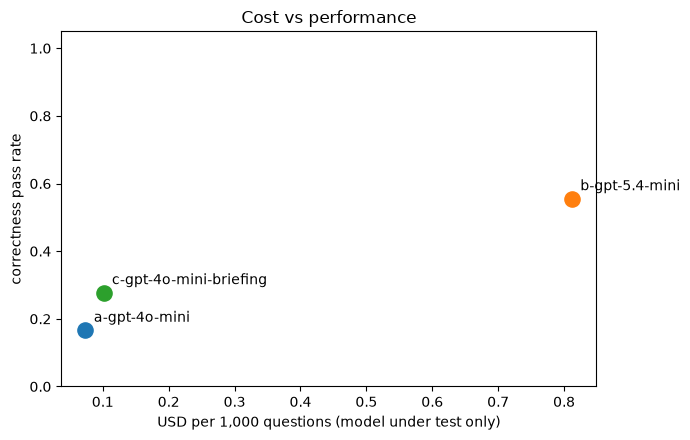

In [35]:
# One row per config: pass rate, avg latency, total cost, cost per example, cost per CORRECT answer
rows, frames = [], []
for name, res in ab_results.items():
    d = res.to_pandas()
    d["example_id"] = d["example_id"].astype(str)
    d = d.merge(meta, on="example_id", how="left")
    model = CONFIGS[name][0]
    p = PRICES[model]
    d["cost"] = d["outputs.prompt_tokens"].fillna(0) / 1e6 * p["input"] + d["outputs.completion_tokens"].fillna(0) / 1e6 * p["output"]
    d["config"] = name
    frames.append(d)
    n_correct = d["feedback.correctness"].astype(float).sum()
    rows.append({
        "config": name, "model": model,
        "pass_rate": d["feedback.correctness"].astype(float).mean(),
        "keyword_pass_rate": d["feedback.keyword_match"].astype(float).mean(),
        "pass_rate_omnibus_qs": d.loc[d["post_cutoff_fact"] == True, "feedback.correctness"].astype(float).mean(),
        "avg_latency_s": d["execution_time"].mean(),
        "total_cost_usd": d["cost"].sum(),
        "cost_per_example_usd": d["cost"].mean(),
        "cost_per_correct_usd": d["cost"].sum() / n_correct if n_correct else float("nan"),
    })
ab = pd.DataFrame(rows).set_index("config")
ab["cost_per_1k_questions_usd"] = ab["cost_per_example_usd"] * 1000
pd.concat(frames).to_csv(OUT / "results_ab_all.csv", index=False)
ab.round(5).to_csv(OUT / "ab_summary.csv")
display(ab.round(4))

# Scatter plot: x = cost per example, y = pass rate, one labelled point per config
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, r in ab.iterrows():
    ax.scatter(r["cost_per_example_usd"] * 1000, r["pass_rate"], s=120)
    ax.annotate(name.removeprefix("config-"), (r["cost_per_example_usd"] * 1000, r["pass_rate"]),
                textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("USD per 1,000 questions (model under test only)"); ax.set_ylabel("correctness pass rate")
ax.set_ylim(0, 1.05); ax.set_title("Cost vs performance")
plt.tight_layout()
plt.savefig(OUT / "cost_vs_performance.png", dpi=120)
plt.show()

 **Before you recommend, think:**
- Is the gap between models bigger than **one or two examples**? With ~20 examples it may be luck (W7/D5).
- Which pass rate is **good enough** for this use case? A cheaper model that meets that bar wins.

### Step 16: `optimization_summary.md`

In [36]:
# Draft built from the computed numbers. I adjust the recommendation sentence after reading the results.
best = ab.sort_values(["pass_rate", "cost_per_example_usd"], ascending=[False, True]).index[0]
table = "\n".join(
    f"| {n} | {r.model} | {r.pass_rate:.0%} | {r.pass_rate_omnibus_qs:.0%} | ${r.cost_per_correct_usd:.5f} | "
    f"${r.cost_per_1k_questions_usd:.3f} | {r.avg_latency_s:.2f}s |"
    for n, r in ab.iterrows())

opt = f'''# Optimization summary

I compared three configurations on the same {len(examples)} questions with the same evaluators (gpt-4o-mini; gpt-5.4-mini;
gpt-4o-mini plus a six-line regulatory briefing on the July 2026 Digital Omnibus). The highest pass rate was
**{best}** ({ab.loc[best, "pass_rate"]:.0%} at ${ab.loc[best, "cost_per_1k_questions_usd"]:.3f} per 1,000 questions).
[fill: best trade-off and when to pick each config. Remember: a gap of 1-2 examples (about 6-11 points) may be luck.]

| Config | Model | Pass rate | Pass rate (Omnibus Qs) | Cost / correct answer | Cost / 1k questions | Avg latency |
|---|---|---|---|---|---|---|
{table}

Prices: gpt-4o-mini $0.15/$0.60, gpt-5.4-mini $0.75/$4.50 per 1M input/output tokens (OpenAI pricing, checked 20 Nov 2026).
Costs cover the model under test only; judge calls cost the same for every config.
'''
Path("optimization_summary.md").write_text(opt, encoding="utf-8")
print(opt)

# Optimization summary

I compared three configurations on the same 18 questions with the same evaluators (gpt-4o-mini; gpt-5.4-mini;
gpt-4o-mini plus a six-line regulatory briefing on the July 2026 Digital Omnibus). The highest pass rate was
**config-b-gpt-5.4-mini** (56% at $0.812 per 1,000 questions).
[fill: best trade-off and when to pick each config. Remember: a gap of 1-2 examples (about 6-11 points) may be luck.]

| Config | Model | Pass rate | Pass rate (Omnibus Qs) | Cost / correct answer | Cost / 1k questions | Avg latency |
|---|---|---|---|---|---|---|
| config-a-gpt-4o-mini | gpt-4o-mini | 17% | 0% | $0.00044 | $0.074 | 1.71s |
| config-b-gpt-5.4-mini | gpt-5.4-mini | 56% | 0% | $0.00146 | $0.812 | 1.99s |
| config-c-gpt-4o-mini-briefing | gpt-4o-mini | 28% | 100% | $0.00036 | $0.101 | 1.54s |

Prices: gpt-4o-mini $0.15/$0.60, gpt-5.4-mini $0.75/$4.50 per 1M input/output tokens (OpenAI pricing, checked 20 Nov 2026).
Costs cover the model under test only; judge calls cost t

---
## Reflection (optional, recommended)
1. What surprised you when you read the failed traces?
2. Did you trust your LLM judge? How did you check it?
3. What would you change in your dataset for a `-v2`?

## Submission checklist
- [ ] GitHub repo with **only** this lab, and a `README.md` (domain + dataset, approach, how to run, LangSmith links, file map)
- [ ] `lab_proof.md` as the **entry point**: code/workflow, one run with its input, the evidence it produced (trace / screenshot), the final output, and one failure or limitation you hit
- [ ] `evaluation_summary.md` at the repo root (one paragraph + optional table)
- [ ] (Optional) `optimization_summary.md` at the repo root
- [ ] Notebook runs top to bottom without errors; descriptive file names (no `lab.ipynb`, `final_v2.py`)
- [ ] `outputs/`: results CSV(s), charts, and LangSmith screenshots (dataset, experiment, one trace)
- [ ] **No API keys** in the repo: `.env` is in `.gitignore`